# Task 4 — การทำนายประเภทเกมจากภาพ

Notebook นี้โหลดโมเดลที่ฝึกแล้วเพื่อจำแนกภาพเกม 5 คลาส โดยใช้ Ensemble ของ DINOv2-Base และ ConvNeXt-Tiny น้ำหนักตัวละ 50% และใช้ TTA สำหรับ ConvNeXt-Tiny

สามารถทำนายบน CPU หรือ GPU ได้โดยไม่ต้องฝึกใหม่ ก่อนรันให้ติดตั้ง dependencies และเตรียมไฟล์โมเดลตาม README


In [2]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
roots = [cwd, *cwd.parents]
candidates = [candidate for p in roots for candidate in (p, p / "Task4", p / "Task4/dist/Task4_submission", p / "dist/Task4_submission")]
BUNDLE_DIR = next((p for p in candidates if (p / "config/ensemble.json").is_file()), None)
if BUNDLE_DIR is None:
    raise FileNotFoundError("เปิดจากชุด Task4_submission หรือกำหนด BUNDLE_DIR ตามตำแหน่งชุดส่ง")
sys.path.insert(0, str(BUNDLE_DIR))
import predict as submission_predict
print("Bundle:", BUNDLE_DIR)


Bundle: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\.ipynb_checkpoints\Task4_relocated_20261126_120625_856702


## 1. กำหนดข้อมูลและตำแหน่งบันทึกผล

กำหนดไฟล์ CSV โฟลเดอร์ภาพ และตำแหน่งบันทึกคำทำนาย โดยค่าเริ่มต้นใช้ภาพ Test ตัวอย่าง 5 ภาพ และประมวลผลบน CPU

ภาพตัวอย่างไม่มีเฉลย จึงใช้สาธิตการทำนายเท่านั้น ไม่สามารถคำนวณความแม่นยำได้

In [3]:
INPUT_CSV = BUNDLE_DIR / "examples/input.csv"
IMAGE_ROOT = BUNDLE_DIR / "examples/images"
SAMPLE_CSV = BUNDLE_DIR / "examples/sample.csv"
OUTPUT_CSV = BUNDLE_DIR / "outputs/example_predictions.csv"
DEVICE = "cpu"  # เปลี่ยนเป็น "auto" หรือ "cuda" เมื่อต้องการใช้ NVIDIA GPU


## 2. ตรวจสอบไฟล์โมเดลและสูตร Ensemble

ตรวจสอบความครบถ้วนและ SHA256 ของไฟล์ พร้อมแสดงสมาชิกและน้ำหนักของ Ensemble โดยโหลดโมเดลจากไฟล์ที่จัดเตรียมไว้ ไม่มีการดาวน์โหลดน้ำหนักเพิ่มเติม

In [4]:
manifest = submission_predict.verify_bundle(BUNDLE_DIR)
ensemble = submission_predict.load_ensemble(BUNDLE_DIR)
display(pd.DataFrame(ensemble["members"])[["name", "weight", "tta", "checkpoint"]])
print("Package files verified:", len(manifest["files"]))


,name,weight,tta,checkpoint
0,dinov2_base,0.5,False,checkpoints/dinov2_base.pt
1,convnext_tiny,0.5,True,checkpoints/convnext_tiny.pt


Package files verified: 53


ใช้ Ensemble ของ DINOv2-Base และ ConvNeXt-Tiny น้ำหนักตัวละ 50% โดย ConvNeXt-Tiny ใช้ TTA แบบภาพปกติและภาพกลับแนวนอน ส่วน DINOv2-Base ไม่ใช้ TTA ทั้งสองโมเดลโหลดน้ำหนักจากโฟลเดอร์ checkpoints และตรวจสอบไฟล์ในชุดส่งผ่านครบ 53 ไฟล์ ก่อนเริ่มทำนาย

## 3. ทำนายและบันทึกผลลัพธ์

รวมความน่าจะเป็นจากทั้งสองโมเดล แล้วเลือกคลาสที่มีค่าสูงสุด บันทึกผลเป็น CSV ที่มีคอลัมน์ id และ task4

เปรียบเทียบกับคำทำนายที่บันทึกไว้เพื่อตรวจสอบการทำซ้ำ โดยผลที่ตรงกันไม่ได้หมายถึงความแม่นยำ เพราะไม่มีเฉลย Test

In [5]:
result = submission_predict.predict_bundle(
    BUNDLE_DIR, INPUT_CSV, IMAGE_ROOT, OUTPUT_CSV,
    sample_csv=SAMPLE_CSV, device=DEVICE,
)
display(result.predictions)
print("Rows:", result.metadata["rows"])
print("SHA256:", result.metadata["csv_sha256"])
expected = pd.read_csv(BUNDLE_DIR / "examples/expected_predictions.csv", dtype={"id": str})
print("ตรงกับ predictions รอบที่บันทึกไว้:", result.predictions.equals(expected))
print("การตรงกันนี้ตรวจ reproducibility ไม่ใช่ accuracy เพราะไม่มี Test labels")


C:\Users\Kittithat\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Predicting dinov2_base: 5 images, device=cpu, flip_tta=False


Predicting convnext_tiny: 5 images, device=cpu, flip_tta=True


,id,task4
0,ANS00001,1
1,ANS00002,2
2,ANS00003,3
3,ANS00004,0
4,ANS00005,3


Rows: 5
SHA256: 4432612068dc92d05a640dc0e6ba921f6b6d99e044155fdb0b0fc5b9b6df1dbf
ตรงกับ predictions รอบที่บันทึกไว้: True
การตรงกันนี้ตรวจ reproducibility ไม่ใช่ accuracy เพราะไม่มี Test labels


ทำนายภาพตัวอย่าง 5 ภาพบน CPU ด้วย Ensemble ของ DINOv2-Base และ ConvNeXt-Tiny แล้วบันทึกผลเป็นคอลัมน์ id และ task4 พร้อมค่า SHA256 สำหรับตรวจสอบไฟล์

## 4. แสดงภาพตัวอย่างพร้อมคำทำนาย

แสดงภาพตัวอย่าง 5 ภาพ พร้อม ID และชื่อเกมที่โมเดลทำนาย เพื่อช่วยตรวจสอบผลลัพธ์เบื้องต้น

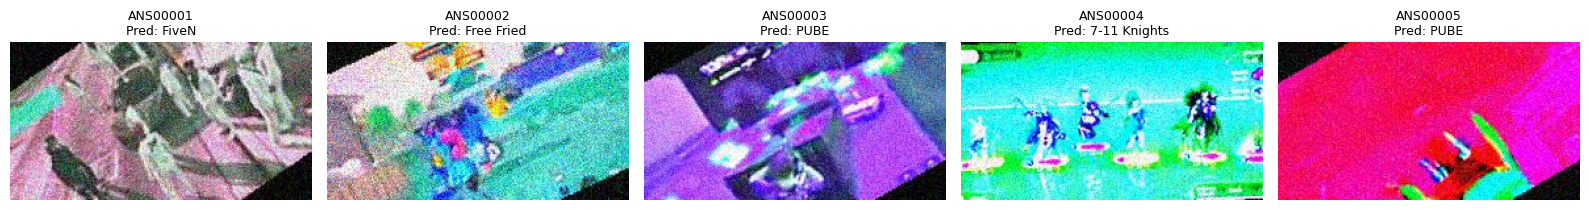

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
input_rows = pd.read_csv(INPUT_CSV, dtype=str).set_index("id")
preview = result.predictions.head(5)
fig, axes = plt.subplots(1, len(preview), figsize=(16, 3), squeeze=False)
for ax, row in zip(axes.flat, preview.itertuples(index=False)):
    with Image.open(IMAGE_ROOT / input_rows.loc[row.id, "file_name"]) as image:
        ax.imshow(image)
    ax.set_title(f"{row.id}\nPred: {ensemble['class_names'][row.task4]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


ภาพแสดงตัวอย่าง Test 5 ภาพพร้อม ID และชื่อเกมที่โมเดลทำนาย แม้ภาพมีจุดรบกวน สีผิดเพี้ยน และมุมเอียง โมเดลยังให้คำทำนายได้ อย่างไรก็ตาม ภาพชุดนี้ไม่มีเฉลย จึงใช้แสดงผลการทำงานเบื้องต้นเท่านั้น ไม่สามารถยืนยันว่าทำนายถูกต้องได้

## 5. การใช้งานกับข้อมูลเพิ่มเติม

หากต้องการทำนายภาพชุดอื่นหรือ Test ทั้งหมด ให้ปรับ INPUT_CSV, IMAGE_ROOT และ SAMPLE_CSV ให้ตรงกับข้อมูล พร้อมกำหนด OUTPUT_CSV สำหรับบันทึกผล แล้วรันขั้นตอนทำนายใหม่โดยไม่ต้องฝึกโมเดล

ไฟล์ข้อมูลต้องมีคอลัมน์ id และ file_name หากระบุ SAMPLE_CSV ต้องมี ID ตรงกับข้อมูลที่ทำนาย

ผลทำนาย Test ทั้งหมด 25,889 ภาพที่จัดเตรียมไว้อยู่ใน results/task4.csv